# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

## Nota sobre las predicciones

Las predicciones ingenuas de los bloques siguientes son ejemplos añadidos retrospectivamente para contrastarlos con los resultados. No son registros de hipótesis escritas antes de ejecutar los experimentos.


# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


### Exploración de Iris

#### Predicción inicial

Creo que cada fila representa una especie distinta y que las clases tendrán cantidades muy diferentes.

#### Implementación y resultados


In [111]:
# Aquí cumple con el primer paso
from sklearn.datasets import load_iris

iris_df = load_iris(as_frame=True)

df = iris_df.frame

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [112]:
df = df.rename(columns={'sepal length (cm)': 'sepal_length'})
df = df.rename(columns={'sepal width (cm)': 'sepal_width'})
df = df.rename(columns={'petal length (cm)': 'petal_length'})
df = df.rename(columns={'petal width (cm)': 'petal_width'})

df.head()

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [113]:
# Ingormación general del dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   target        150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [114]:
# Listamos las distintas clases en el target junto con su conteo
df['target'].value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

In [115]:
# Clases definidas para iris (0) setosa, (1) versicolor, (2) virginica
iris_df.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [116]:
# Construyo X como matríz de caracteristicas y y como vector de etiquetas
X = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
y = df['target']

In [117]:
X

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [118]:
# Dimensiones de la matríz de caracteristicas
X.shape

(150, 4)

In [119]:
y

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: target, Length: 150, dtype: int64

In [120]:
# dimensiones del vector de etiquetas
y.shape

(150,)

#### Interpretación

Cada fila representa una flor; hay 150 ejemplos, cuatro características y tres clases con 50 flores cada una.

#### Respuestas a las preguntas planteadas

**¿Qué representan las instancias, las características y las dimensiones?**
Las características son longitud y ancho de sépalos y pétalos, en cm. X tiene forma (150, 4) e y (150,).


# 2. Comparación de clasificadores

## Preguntas para la predicción inicial

1. ¿Qué modelos serán sensibles a las escalas?
2. ¿Qué modelo producirá fronteras más simples?
3. ¿Por qué no sabemos de antemano cuál será mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Preguntas que se responderán al final

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?


### Clasificación: comparación inicial

#### Predicción inicial

Creo que solo los árboles necesitan escalar y que el MLP ganará por ser más complejo.
Un árbol profundo debería tener la frontera más sencilla y acertar casi todo.

#### Implementación y resultados


In [121]:
from sklearn.model_selection import train_test_split

# Separo el 20% del dataset para test
X_restante, X_test, y_restante, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Separo el 25% del restante para validation
# Distribución final: 60% train, 20% validación y 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_restante,
    y_restante,
    test_size=0.25,
    stratify=y_restante,
    random_state=42
)

In [122]:
# Creacion de modelos 

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier

modelos = {
    "Naive Bayes": make_pipeline(
        StandardScaler(),
        GaussianNB()
    ),

    "Regresión logística": make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=1000)
    ),

    "SVM lineal": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=1.0)
    ),

    "Árbol de decisión": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier(max_depth=3, random_state=42)
    ),

    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=100,
            max_depth=3,
            random_state=42
        )
    ),

    "Gradient Boosting": make_pipeline(
        StandardScaler(),
        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=2,
            random_state=42
        )
    ),

    "MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(16,),
            activation="relu",
            solver="lbfgs",
            alpha=0.001,
            max_iter=2000,
            random_state=42
        )
    )
}

In [123]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

resultados_validacion = []

for nombre, modelo in modelos.items():
    # Ajusta el escalador y entrena usando solamente train.
    modelo.fit(X_train, y_train)

    # Predice validación con el escalador aprendido en train.
    predicciones = modelo.predict(X_val)

    resultados_validacion.append({
        "Modelo": nombre,
        "Accuracy validación": accuracy_score(y_val, predicciones),
        "F1 macro validación": f1_score(
            y_val,
            predicciones,
            average="macro"
        )
    })

tabla_validacion = pd.DataFrame(resultados_validacion)

tabla_validacion.sort_values(
    by="F1 macro validación",
    ascending=False
)

,Modelo,Accuracy validación,F1 macro validación
0,Naive Bayes,0.933333,0.933333
1,Regresión logística,0.933333,0.933333
2,SVM lineal,0.933333,0.933333
4,Random Forest,0.933333,0.933333
5,Gradient Boosting,0.933333,0.933333
6,MLP,0.933333,0.933333
3,Árbol de decisión,0.900000,0.899749


#### Interpretación

Seis modelos empatan en validación con 0.9333; el árbol obtiene 0.90. Mayor complejidad no asegura mayor precisión.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
La regresión logística, SVM y MLP son sensibles al escalamiento; los árboles normalmente no lo necesitan.
Los modelos lineales tienen fronteras más simples y el mejor modelo debe comprobarse con datos.


### Clasificación: ajuste de Árbol de decisión

#### Predicción inicial

Creo que cualquier aumento de profundidad mejorará validación hasta eliminar todos los errores.

#### Implementación y resultados


In [124]:
from sklearn.metrics import accuracy_score, f1_score

resultados_arbol = []

for profundidad in [2, 3, 4]:
    for minimo_hoja in [1, 2, 4]:
        modelo = make_pipeline(
            StandardScaler(),
            DecisionTreeClassifier(
                max_depth=profundidad,
                min_samples_leaf=minimo_hoja,
                random_state=42
            )
        )

        modelo.fit(X_train, y_train)

        pred_train = modelo.predict(X_train)
        pred_val = modelo.predict(X_val)

        resultados_arbol.append({
            "max_depth": profundidad,
            "min_samples_leaf": minimo_hoja,
            "Accuracy train": accuracy_score(y_train, pred_train),
            "Accuracy val": accuracy_score(y_val, pred_val),
            "F1 macro train": f1_score(
                y_train, pred_train, average="macro"
            ),
            "F1 macro val": f1_score(
                y_val, pred_val, average="macro"
            )
        })

tabla_arbol = pd.DataFrame(resultados_arbol)

tabla_arbol.sort_values(
    by="F1 macro val",
    ascending=False
)

,max_depth,min_samples_leaf,Accuracy train,Accuracy val,F1 macro train,F1 macro val
6,4,1,1.000000,0.933333,1.000000,0.933333
0,2,1,0.988889,0.900000,0.988886,0.899749
1,2,2,0.988889,0.900000,0.988886,0.899749
3,3,1,0.988889,0.900000,0.988886,0.899749
2,2,4,0.988889,0.900000,0.988886,0.899749
4,3,2,0.988889,0.900000,0.988886,0.899749
5,3,4,0.988889,0.900000,0.988886,0.899749
7,4,2,0.988889,0.900000,0.988886,0.899749
8,4,4,0.988889,0.900000,0.988886,0.899749


#### Interpretación

Solo profundidad 4 y mínimo de una muestra por hoja mejora validación a 0.9333. El resto queda en 0.90.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Elegir max_depth=4 y min_samples_leaf=1 entre los valores probados.


### Clasificación: ajuste de Naive Bayes

#### Predicción inicial

Creo que aumentar var_smoothing hará que el modelo aprenda más y acierte todas las flores.

#### Implementación y resultados


In [125]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

resultados_nb = []

for configuracion in ParameterGrid({'var_smoothing': [1e-11, 1e-09, 1e-07]}):
    modelo = make_pipeline(
        StandardScaler(),
        GaussianNB(**configuracion, **{})
    )
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    resultados_nb.append({
        **configuracion,
        "Accuracy train": accuracy_score(y_train, pred_train),
        "Accuracy val": accuracy_score(y_val, pred_val),
        "F1 macro train": f1_score(y_train, pred_train, average="macro"),
        "F1 macro val": f1_score(y_val, pred_val, average="macro")
    })

tabla_nb = pd.DataFrame(resultados_nb)
tabla_nb.sort_values(by="F1 macro val", ascending=False, kind="stable")


,var_smoothing,Accuracy train,Accuracy val,F1 macro train,F1 macro val
0,1.000000e-11,0.977778,0.933333,0.977753,0.933333
1,1.000000e-09,0.977778,0.933333,0.977753,0.933333
2,1.000000e-07,0.977778,0.933333,0.977753,0.933333


#### Interpretación

Los tres valores producen las mismas métricas de validación. Cambiar el suavizado no mejora este resultado.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar var_smoothing=1e-9, porque las alternativas empatan.


### Clasificación: ajuste de Regresión logística

#### Predicción inicial

Creo que C=10 será mejor porque permitirá ajustar más los ejemplos de entrenamiento.

#### Implementación y resultados


In [126]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

resultados_logistica = []

for configuracion in ParameterGrid({'C': [0.1, 1.0, 10.0]}):
    modelo = make_pipeline(
        StandardScaler(),
        LogisticRegression(**configuracion, **{'max_iter': 1000})
    )
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    resultados_logistica.append({
        **configuracion,
        "Accuracy train": accuracy_score(y_train, pred_train),
        "Accuracy val": accuracy_score(y_val, pred_val),
        "F1 macro train": f1_score(y_train, pred_train, average="macro"),
        "F1 macro val": f1_score(y_val, pred_val, average="macro")
    })

tabla_logistica = pd.DataFrame(resultados_logistica)
tabla_logistica.sort_values(by="F1 macro val", ascending=False, kind="stable")


,C,Accuracy train,Accuracy val,F1 macro train,F1 macro val
1,1.0,0.977778,0.933333,0.977778,0.933333
2,10.0,0.977778,0.933333,0.977778,0.933333
0,0.1,0.955556,0.866667,0.955556,0.865320


#### Interpretación

C=1 y C=10 empatan; C=0.1 empeora validación. Un valor mayor no aporta aquí una mejora.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Elegir C=1: mantiene el resultado con mayor regularización que C=10.


### Clasificación: ajuste de SVM lineal

#### Predicción inicial

Creo que C=10 será mejor tanto en train como en validación porque castigará más los errores.

#### Implementación y resultados


In [127]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

resultados_svm = []

for configuracion in ParameterGrid({'C': [0.1, 1.0, 10.0]}):
    modelo = make_pipeline(
        StandardScaler(),
        SVC(**configuracion, **{'kernel': 'linear'})
    )
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    resultados_svm.append({
        **configuracion,
        "Accuracy train": accuracy_score(y_train, pred_train),
        "Accuracy val": accuracy_score(y_val, pred_val),
        "F1 macro train": f1_score(y_train, pred_train, average="macro"),
        "F1 macro val": f1_score(y_val, pred_val, average="macro")
    })

tabla_svm = pd.DataFrame(resultados_svm)
tabla_svm.sort_values(by="F1 macro val", ascending=False, kind="stable")


,C,Accuracy train,Accuracy val,F1 macro train,F1 macro val
0,0.1,0.977778,0.933333,0.977753,0.933333
1,1.0,0.977778,0.933333,0.977778,0.933333
2,10.0,0.988889,0.900000,0.988886,0.899749


#### Interpretación

C=10 mejora train pero empeora validación. C=0.1 y C=1 empatan con F1 macro de 0.9333.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Elegir C=0.1 por su mayor regularización entre las opciones empatadas.


### Clasificación: ajuste de Random Forest

#### Predicción inicial

Creo que los árboles más profundos ganarán, especialmente si permiten hojas con una sola flor.

#### Implementación y resultados


In [128]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

resultados_rf = []

for configuracion in ParameterGrid({'max_depth': [2, 3, 4], 'min_samples_leaf': [1, 2, 4]}):
    modelo = make_pipeline(
        StandardScaler(),
        RandomForestClassifier(**configuracion, **{'n_estimators': 100, 'random_state': 42})
    )
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    resultados_rf.append({
        **configuracion,
        "Accuracy train": accuracy_score(y_train, pred_train),
        "Accuracy val": accuracy_score(y_val, pred_val),
        "F1 macro train": f1_score(y_train, pred_train, average="macro"),
        "F1 macro val": f1_score(y_val, pred_val, average="macro")
    })

tabla_rf = pd.DataFrame(resultados_rf)
tabla_rf.sort_values(by="F1 macro val", ascending=False, kind="stable")


,max_depth,min_samples_leaf,Accuracy train,Accuracy val,F1 macro train,F1 macro val
2,2,4,0.988889,0.933333,0.988886,0.933333
3,3,1,1.000000,0.933333,1.000000,0.933333
4,3,2,1.000000,0.933333,1.000000,0.933333
5,3,4,1.000000,0.933333,1.000000,0.933333
6,4,1,1.000000,0.933333,1.000000,0.933333
7,4,2,1.000000,0.933333,1.000000,0.933333
8,4,4,1.000000,0.933333,1.000000,0.933333
0,2,1,0.988889,0.900000,0.988886,0.899749
1,2,2,0.988889,0.900000,0.988886,0.899749


#### Interpretación

Profundidad 2 y mínimo de cuatro ejemplos por hoja iguala el mejor resultado de árboles mayores.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Elegir max_depth=2 y min_samples_leaf=4, manteniendo 100 árboles.


### Clasificación: ajuste de Gradient Boosting

#### Predicción inicial

Creo que añadir más árboles siempre reducirá el error en validación.

#### Implementación y resultados


In [129]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

resultados_gb = []

for configuracion in ParameterGrid({'learning_rate': [0.05, 0.1, 0.2], 'n_estimators': [50, 100, 150]}):
    modelo = make_pipeline(
        StandardScaler(),
        GradientBoostingClassifier(**configuracion, **{'max_depth': 2, 'random_state': 42})
    )
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    resultados_gb.append({
        **configuracion,
        "Accuracy train": accuracy_score(y_train, pred_train),
        "Accuracy val": accuracy_score(y_val, pred_val),
        "F1 macro train": f1_score(y_train, pred_train, average="macro"),
        "F1 macro val": f1_score(y_val, pred_val, average="macro")
    })

tabla_gb = pd.DataFrame(resultados_gb)
tabla_gb.sort_values(by="F1 macro val", ascending=False, kind="stable")


,learning_rate,n_estimators,Accuracy train,Accuracy val,F1 macro train,F1 macro val
1,0.05,100,1.0,0.933333,1.0,0.933333
2,0.05,150,1.0,0.933333,1.0,0.933333
3,0.10,50,1.0,0.933333,1.0,0.933333
4,0.10,100,1.0,0.933333,1.0,0.933333
5,0.10,150,1.0,0.933333,1.0,0.933333
7,0.20,100,1.0,0.933333,1.0,0.933333
8,0.20,150,1.0,0.933333,1.0,0.933333
0,0.05,50,1.0,0.900000,1.0,0.899749
6,0.20,50,1.0,0.900000,1.0,0.899749


#### Interpretación

Con 50 etapas y learning_rate=0.1 se alcanza el mismo F1 que con 100 o 150 etapas.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Elegir 50 etapas y learning_rate=0.1 para mantener el resultado con menos árboles.


### Clasificación: ajuste de MLP

#### Predicción inicial

Creo que 32 neuronas siempre serán mejores que 8 porque pueden memorizar más detalles.

#### Implementación y resultados


In [130]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

resultados_mlp = []

for configuracion in ParameterGrid({'hidden_layer_sizes': [(8,), (16,), (32,)], 'alpha': [0.0001, 0.001, 0.01]}):
    modelo = make_pipeline(
        StandardScaler(),
        MLPClassifier(**configuracion, **{'activation': 'relu', 'solver': 'lbfgs', 'max_iter': 2000, 'random_state': 42})
    )
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    resultados_mlp.append({
        **configuracion,
        "Accuracy train": accuracy_score(y_train, pred_train),
        "Accuracy val": accuracy_score(y_val, pred_val),
        "F1 macro train": f1_score(y_train, pred_train, average="macro"),
        "F1 macro val": f1_score(y_val, pred_val, average="macro")
    })

tabla_mlp = pd.DataFrame(resultados_mlp)
tabla_mlp.sort_values(by="F1 macro val", ascending=False, kind="stable")


,alpha,hidden_layer_sizes,Accuracy train,Accuracy val,F1 macro train,F1 macro val
0,0.0001,"(8,)",0.977778,0.933333,0.977778,0.933333
3,0.0010,"(8,)",0.977778,0.933333,0.977778,0.933333
4,0.0010,"(16,)",1.000000,0.933333,1.000000,0.933333
5,0.0010,"(32,)",1.000000,0.933333,1.000000,0.933333
6,0.0100,"(8,)",0.977778,0.933333,0.977778,0.933333
7,0.0100,"(16,)",1.000000,0.933333,1.000000,0.933333
8,0.0100,"(32,)",1.000000,0.900000,1.000000,0.901504
1,0.0001,"(16,)",1.000000,0.900000,1.000000,0.899749
2,0.0001,"(32,)",1.000000,0.900000,1.000000,0.899749


#### Interpretación

Ocho neuronas igualan el mejor F1 de validación. Algunas redes mayores incluso empeoran.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Elegir ocho neuronas y alpha=0.01, la mayor penalización probada que mantiene ese resultado.


### Clasificación: configuraciones congeladas

#### Predicción inicial

Creo que para elegir debo priorizar el modelo que más acierta en train, incluso si pierde en validación.

#### Implementación y resultados


### Selección y congelación de las configuraciones finales

Se selecciona el mayor F1 macro de validación entre las configuraciones probadas, con accuracy de validación como complemento. En los empates se favorecen estructuras menores o una regularización más fuerte; si no cambia la complejidad ni las métricas, se conserva el valor inicial. Las métricas de train ayudan a interpretar el ajuste, pero no se usan para premiar la memorización. Una mayor regularización no reduce necesariamente el número de parámetros ni el costo computacional.

| Modelo | Configuración final | Accuracy train | Accuracy val | F1 macro val | Justificación |
|---|---|---:|---:|---:|---|
| Naive Bayes | `var_smoothing=1e-9` | 0.977778 | 0.933333 | 0.933333 | Los tres valores empatan y mantienen la misma estructura; se conserva el valor inicial. |
| Regresión logística | `C=1.0`, `max_iter=1000` | 0.977778 | 0.933333 | 0.933333 | Empata con C=10 y aplica mayor regularización. C=0.1 reduce el desempeño de validación. |
| SVM lineal | `kernel="linear"`, `C=0.1` | 0.977778 | 0.933333 | 0.933333 | Empata con C=1 y aplica mayor regularización. C=10 aumenta accuracy de train, pero empeora validación. Se mantiene la familia lineal solicitada. |
| Árbol de decisión | `max_depth=4`, `min_samples_leaf=1`, `random_state=42` | 1.000000 | 0.933333 | 0.933333 | Es la única configuración probada que alcanza el mejor F1 de validación. La complejidad adicional mejora un acierto frente a la configuración inicial; no se afirma que garantice mejor generalización. |
| Random Forest | `n_estimators=100`, `max_depth=2`, `min_samples_leaf=4`, `random_state=42` | 0.988889 | 0.933333 | 0.933333 | Iguala el mejor resultado con árboles menos profundos y hojas con más ejemplos, sin necesitar accuracy perfecto en train. |
| Gradient Boosting | `n_estimators=50`, `learning_rate=0.1`, `max_depth=2`, `random_state=42` | 1.000000 | 0.933333 | 0.933333 | Iguala el mejor resultado con menos etapas de boosting que las alternativas de 100 y 150. Entre las opciones de 50 etapas, solo learning_rate=0.1 alcanza ese F1. |
| MLP | `hidden_layer_sizes=(8,)`, `alpha=0.01`, `activation="relu"`, `solver="lbfgs"`, `max_iter=2000`, `random_state=42` | 0.977778 | 0.933333 | 0.933333 | La capa de 8 neuronas empata con redes mayores y tiene menos pesos. Entre las opciones de 8 neuronas se elige la mayor regularización probada que mantiene el resultado. |

Todos los modelos seleccionados alcanzan el mismo accuracy y F1 macro de validación (0.933333): 28 aciertos de 30 ejemplos. Esto no implica que cometan los mismos errores ni demuestra equivalencia en datos nuevos. Las conclusiones están limitadas a esta partición y esta búsqueda pequeña.

Se congelan estas decisiones antes de consultar test. El diccionario siguiente crea pipelines nuevos, todavía sin entrenar. Para la evaluación final se ajustarán con `X_train, y_train`, conservando el protocolo usado en las comparaciones; StandardScaler aprenderá sus estadísticas únicamente de train. Después se obtendrán las métricas y matrices de confusión sobre test sin iniciar nuevos ajustes.


In [131]:
# Configuraciones finales congeladas; estos pipelines aún no están entrenados.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

modelos_finales = {
    "Naive Bayes": make_pipeline(
        StandardScaler(), GaussianNB(var_smoothing=1e-9)
    ),
    "Regresión logística": make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)
    ),
    "SVM lineal": make_pipeline(
        StandardScaler(), SVC(kernel="linear", C=0.1)
    ),
    "Árbol de decisión": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier(max_depth=4, min_samples_leaf=1, random_state=42)
    ),
    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier(n_estimators=100, max_depth=2,
                               min_samples_leaf=4, random_state=42)
    ),
    "Gradient Boosting": make_pipeline(
        StandardScaler(),
        GradientBoostingClassifier(n_estimators=50, learning_rate=0.1,
                                   max_depth=2, random_state=42)
    ),
    "MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(8,), alpha=0.01, activation="relu",
                      solver="lbfgs", max_iter=2000, random_state=42)
    )
}


#### Interpretación

La selección usa validación y conserva opciones más sencillas en los empates. Train perfecto no es el criterio de elección.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Mantener el diccionario modelos_finales sin nuevos ajustes al observar test.


### Clasificación: evaluación final en test

#### Predicción inicial

Creo que los modelos que aciertan todo train también acertarán todas las flores de test.

#### Implementación y resultados


In [132]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

resultados_finales = []
predicciones_test_finales = {}

for nombre, modelo in modelos_finales.items():
    # Configuración congelada: fit ajusta scaler y clasificador solo con train.
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)
    predicciones_test_finales[nombre] = pred_test

    clasificador = modelo.steps[-1][1]
    parametros = clasificador.get_params()
    claves = {
        "Naive Bayes": ["var_smoothing"],
        "Regresión logística": ["C", "max_iter"],
        "SVM lineal": ["kernel", "C"],
        "Árbol de decisión": ["max_depth", "min_samples_leaf", "random_state"],
        "Random Forest": ["n_estimators", "max_depth", "min_samples_leaf", "random_state"],
        "Gradient Boosting": ["n_estimators", "learning_rate", "max_depth", "random_state"],
        "MLP": ["hidden_layer_sizes", "alpha", "activation", "solver", "max_iter", "random_state"]
    }[nombre]

    resultados_finales.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler (ajustado en train)",
        "Hiperparámetros principales": "; ".join(
            f"{clave}={parametros[clave]!r}" for clave in claves
        ),
        "Accuracy train": accuracy_score(y_train, pred_train),
        "Accuracy test": accuracy_score(y_test, pred_test),
        "F1 macro train": f1_score(y_train, pred_train, average="macro"),
        "F1 macro test": f1_score(y_test, pred_test, average="macro")
    })

tabla_final = pd.DataFrame(resultados_finales)
tabla_final["Brecha accuracy (train - test)"] = (
    tabla_final["Accuracy train"] - tabla_final["Accuracy test"]
)
tabla_final["Brecha F1 (train - test)"] = (
    tabla_final["F1 macro train"] - tabla_final["F1 macro test"]
)

# Tabla requerida por el notebook.
tabla_prueba = tabla_final[[
    "Modelo", "Transformación", "Hiperparámetros principales",
    "Accuracy test", "F1 macro test"
]].rename(columns={
    "Accuracy test": "Accuracy de prueba",
    "F1 macro test": "F1 macro de prueba"
})
display(tabla_prueba)

# Comparación de entrenamiento frente a prueba.
tabla_comparacion = tabla_final[[
    "Modelo", "Accuracy train", "Accuracy test", "F1 macro train",
    "F1 macro test", "Brecha accuracy (train - test)",
    "Brecha F1 (train - test)"
]]
display(tabla_comparacion)


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Naive Bayes,StandardScaler (ajustado en train),var_smoothing=1e-09,0.933333,0.933333
1,Regresión logística,StandardScaler (ajustado en train),C=1.0; max_iter=1000,0.933333,0.933333
2,SVM lineal,StandardScaler (ajustado en train),kernel='linear'; C=0.1,0.933333,0.933333
3,Árbol de decisión,StandardScaler (ajustado en train),max_depth=4; min_samples_leaf=1; random_state=42,0.933333,0.933333
4,Random Forest,StandardScaler (ajustado en train),n_estimators=100; max_depth=2; min_samples_lea...,0.933333,0.933333
5,Gradient Boosting,StandardScaler (ajustado en train),n_estimators=50; learning_rate=0.1; max_depth=...,0.933333,0.933333
6,MLP,StandardScaler (ajustado en train),"hidden_layer_sizes=(8,); alpha=0.01; activatio...",0.933333,0.933333


,Modelo,Accuracy train,Accuracy test,F1 macro train,F1 macro test,Brecha accuracy (train - test),Brecha F1 (train - test)
0,Naive Bayes,0.977778,0.933333,0.977753,0.933333,0.044444,0.044420
1,Regresión logística,0.977778,0.933333,0.977778,0.933333,0.044444,0.044444
2,SVM lineal,0.977778,0.933333,0.977753,0.933333,0.044444,0.044420
3,Árbol de decisión,1.000000,0.933333,1.000000,0.933333,0.066667,0.066667
4,Random Forest,0.988889,0.933333,0.988886,0.933333,0.055556,0.055552
5,Gradient Boosting,1.000000,0.933333,1.000000,0.933333,0.066667,0.066667
6,MLP,0.977778,0.933333,0.977778,0.933333,0.044444,0.044444


### Resultados finales de clasificación

Evaluación sobre la misma partición de prueba, con configuraciones congeladas y estandarización ajustada únicamente con entrenamiento.

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---:|---:|
| Naive Bayes | StandardScaler (ajustado en train) | `var_smoothing=1e-09` | 0.933333 | 0.933333 |
| Regresión logística | StandardScaler (ajustado en train) | `C=1.0; max_iter=1000` | 0.933333 | 0.933333 |
| SVM lineal | StandardScaler (ajustado en train) | `kernel='linear'; C=0.1` | 0.933333 | 0.933333 |
| Árbol de decisión | StandardScaler (ajustado en train) | `max_depth=4; min_samples_leaf=1; random_state=42` | 0.933333 | 0.933333 |
| Random Forest | StandardScaler (ajustado en train) | `n_estimators=100; max_depth=2; min_samples_leaf=4; random_state=42` | 0.933333 | 0.933333 |
| Gradient Boosting | StandardScaler (ajustado en train) | `n_estimators=50; learning_rate=0.1; max_depth=2; random_state=42` | 0.933333 | 0.933333 |
| MLP | StandardScaler (ajustado en train) | `hidden_layer_sizes=(8,); alpha=0.01; activation='relu'; solver='lbfgs'; max_iter=2000; random_state=42` | 0.933333 | 0.933333 |


#### Interpretación

Todos aciertan 28 de 30 flores en test. El árbol y Gradient Boosting pierden su ventaja de entrenamiento.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Los siete empatan en accuracy y F1 macro de prueba: 0.9333. Esto no demuestra equivalencia en cualquier conjunto.


### Matriz de confusión: Naive Bayes

#### Predicción inicial

Creo que con accuracy alto todos los errores serán de setosa y las otras especies se distinguirán perfectamente.

#### Implementación y resultados


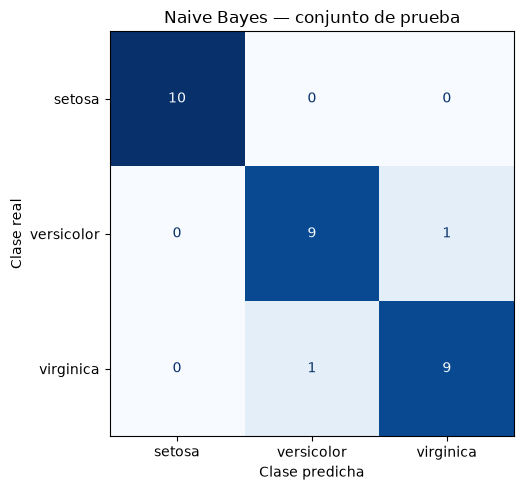

In [133]:
# Matriz de confusión de Naive Bayes sobre test.
# Ejecutar previamente la celda de evaluación final.
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz_nb = confusion_matrix(
    y_test, predicciones_test_finales['Naive Bayes'], labels=[0, 1, 2]
)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_nb,
    display_labels=iris_df.target_names
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Naive Bayes — conjunto de prueba")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
fig.tight_layout()
plt.show()


#### Interpretación

Setosa se clasifica sin errores. Hay una versicolor predicha como virginica y una virginica como versicolor.

#### Respuestas a las preguntas planteadas

**¿Qué clases se confunden?**
El error se concentra entre versicolor y virginica; la matriz por sí sola no demuestra su causa.


### Matriz de confusión: SVM lineal

#### Predicción inicial

Creo que con accuracy alto todos los errores serán de setosa y las otras especies se distinguirán perfectamente.

#### Implementación y resultados


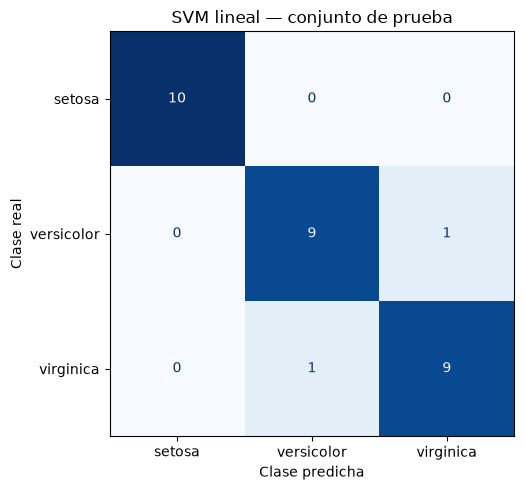

In [134]:
# Matriz de confusión de SVM lineal sobre test.
# Ejecutar previamente la celda de evaluación final.
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz_svm = confusion_matrix(
    y_test, predicciones_test_finales['SVM lineal'], labels=[0, 1, 2]
)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_svm,
    display_labels=iris_df.target_names
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("SVM lineal — conjunto de prueba")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
fig.tight_layout()
plt.show()


#### Interpretación

Setosa se clasifica sin errores. Hay una versicolor predicha como virginica y una virginica como versicolor.

#### Respuestas a las preguntas planteadas

**¿Qué clases se confunden?**
El error se concentra entre versicolor y virginica; la matriz por sí sola no demuestra su causa.


### Matriz de confusión: MLP

#### Predicción inicial

Creo que con accuracy alto todos los errores serán de setosa y las otras especies se distinguirán perfectamente.

#### Implementación y resultados


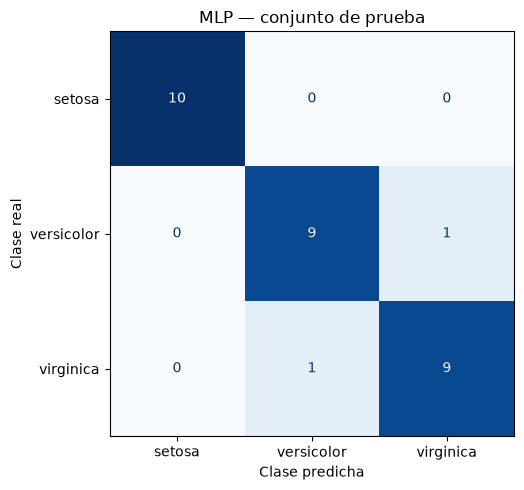

In [135]:
# Matriz de confusión de MLP sobre test.
# Ejecutar previamente la celda de evaluación final.
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz_mlp = confusion_matrix(
    y_test, predicciones_test_finales['MLP'], labels=[0, 1, 2]
)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_mlp,
    display_labels=iris_df.target_names
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("MLP — conjunto de prueba")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
fig.tight_layout()
plt.show()


#### Interpretación

Setosa se clasifica sin errores. Hay una versicolor predicha como virginica y una virginica como versicolor.

#### Respuestas a las preguntas planteadas

**¿Qué clases se confunden?**
El error se concentra entre versicolor y virginica; la matriz por sí sola no demuestra su causa.


### Respuestas finales de clasificación

1. **Mejor desempeño:** los siete modelos empatan con accuracy y F1 macro de 0.9333 en test.
2. **Más sencillo de programar:** Naive Bayes requirió poca configuración y solo un hiperparámetro de ajuste.
3. **Accuracy y F1 macro:** sí, ambos muestran el mismo empate en este experimento.
4. **Macro y micro:** macro da el mismo peso a cada clase; micro reúne los aciertos y errores antes de calcular la métrica.
5. **Aporte del MLP:** puede aprender relaciones más complejas, pero aquí no superó a los modelos lineales.


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Pregunta para la predicción inicial

¿Un modelo más flexible producirá siempre menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Preguntas que se responderán al final

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?


### Regresión: comparación inicial

#### Predicción inicial

Creo que un modelo más flexible siempre generaliza mejor y que el MLP ganará por tener más capacidad.

#### Implementación y resultados


In [5]:
from sklearn.datasets import load_diabetes

# Cargar el dataset
diabetes = load_diabetes()

# Acceder a las características (variables independientes) y a la etiqueta (objetivo)
X, y = diabetes.data, diabetes.target

In [6]:
X.shape

(442, 10)

In [7]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diabetes_reg = load_diabetes()
X_reg = pd.DataFrame(diabetes_reg.data, columns=diabetes_reg.feature_names)
y_reg = pd.Series(diabetes_reg.target, name="progresion")
X_restante_reg, X_test_reg, y_restante_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)
X_train_reg, X_val_reg, y_train_reg, y_val_reg = train_test_split(
    X_restante_reg, y_restante_reg, test_size=0.25, random_state=42
)
display(pd.DataFrame({"Partición": ["Train", "Validación", "Test"],
                      "Instancias": [len(y_train_reg), len(y_val_reg), len(y_test_reg)]}))

def metricas_regresion(real, pred):
    return {"MAE": mean_absolute_error(real, pred),
            "RMSE": np.sqrt(mean_squared_error(real, pred)),
            "R²": r2_score(real, pred)}

def crear_modelo_regresion(nombre, parametros):
    clases = {"Regresión lineal": LinearRegression, "Ridge": Ridge,
              "Lasso": Lasso, "kNN": KNeighborsRegressor,
              "Árbol": DecisionTreeRegressor, "Random Forest": RandomForestRegressor,
              "Gradient Boosting": GradientBoostingRegressor, "MLP": MLPRegressor}
    estimador = clases[nombre](**parametros)
    if nombre in ["Regresión lineal", "Ridge", "Lasso", "kNN", "MLP"]:
        estimador = make_pipeline(StandardScaler(), estimador)
    if nombre == "MLP":
        # fit ajusta el escalador de y solo con train;
        # predict devuelve automáticamente y a su escala original.
        estimador = TransformedTargetRegressor(regressor=estimador, transformer=StandardScaler())
    return estimador

configuraciones_iniciales_reg = {
    "Regresión lineal": {},
    "Ridge": {"alpha": 1.0},
    "Lasso": {"alpha": 1.0, "max_iter": 10000},
    "kNN": {"n_neighbors": 5, "weights": "uniform"},
    "Árbol": {"max_depth": 3, "min_samples_leaf": 1, "random_state": 42},
    "Random Forest": {"n_estimators": 100, "max_depth": 5, "min_samples_leaf": 1, "random_state": 42},
    "Gradient Boosting": {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 2, "random_state": 42},
    "MLP": {"hidden_layer_sizes": (16,), "alpha": 0.001, "activation": "relu",
            "solver": "adam", "max_iter": 2000, "early_stopping": True, "random_state": 42}
}
modelos_iniciales_reg = {n: crear_modelo_regresion(n, p) for n,p in configuraciones_iniciales_reg.items()}
resultados_iniciales_reg = []
for nombre, modelo in modelos_iniciales_reg.items():
    modelo.fit(X_train_reg, y_train_reg)
    fila = {"Modelo": nombre}
    for etiqueta, x, y in [("train", X_train_reg, y_train_reg), ("val", X_val_reg, y_val_reg)]:
        fila.update({f"{k} {etiqueta}": v for k,v in metricas_regresion(y, modelo.predict(x)).items()})
    resultados_iniciales_reg.append(fila)
tabla_inicial_reg = pd.DataFrame(resultados_iniciales_reg)
display(tabla_inicial_reg.sort_values("RMSE val"))


,Partición,Instancias
0,Train,264
1,Validación,89
2,Test,89


,Modelo,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val
2,Lasso,44.115428,54.912377,0.514958,42.470345,51.060247,0.524140
1,Ridge,43.790833,54.643849,0.519691,42.723050,51.103145,0.523341
0,Regresión lineal,43.793527,54.610364,0.520279,42.938900,51.193714,0.521650
6,Gradient Boosting,30.584540,38.208602,0.765166,44.048708,53.973865,0.468284
5,Random Forest,31.340152,38.098294,0.766520,44.174741,54.700337,0.453874
7,MLP,45.021347,55.454450,0.505335,43.755129,55.306290,0.441707
3,kNN,41.348485,52.383979,0.558597,45.292135,56.833330,0.410452
4,Árbol,43.105593,53.579488,0.538219,46.569194,58.226727,0.381189


#### Interpretación

Lasso obtiene el menor RMSE inicial de validación. Los modelos más flexibles no son los mejores en esta comparación.

#### Respuestas a las preguntas planteadas

**¿Un modelo más flexible produce siempre menor error?**
La flexibilidad no garantiza menor error en datos nuevos; hace falta comprobarlo en validación.


### Herramienta para comparar configuraciones

Se ajusta con train y se compara con validación; test se reserva para la evaluación final.


In [8]:
resultados_ajustes_reg = {}
modelos_candidatos_reg = {}

def comparar_configuraciones_reg(nombre, rejilla):
    filas, candidatos = [], []
    for cambios in ParameterGrid(rejilla):
        parametros = {**configuraciones_iniciales_reg[nombre], **cambios}
        modelo = crear_modelo_regresion(nombre, parametros)
        modelo.fit(X_train_reg, y_train_reg)
        fila = {**cambios, "Configuración": parametros}
        for etiqueta, x, y in [("train", X_train_reg, y_train_reg), ("val", X_val_reg, y_val_reg)]:
            fila.update({f"{k} {etiqueta}": v for k,v in metricas_regresion(y, modelo.predict(x)).items()})
        if nombre in ["Ridge", "Lasso"]:
            coef = modelo.steps[-1][1].coef_
            fila["Norma L2 coeficientes"] = np.linalg.norm(coef)
            fila["Coeficientes nulos"] = int(np.count_nonzero(coef == 0))
            fila["Coeficientes"] = dict(zip(diabetes_reg.feature_names, coef.tolist()))
        filas.append(fila)
        candidatos.append(modelo)
    tabla = pd.DataFrame(filas)
    resultados_ajustes_reg[nombre] = tabla
    modelos_candidatos_reg[nombre] = candidatos
    return tabla.sort_values(["RMSE val", "MAE val"], kind="stable")


### Regresión: ajuste de Regresión lineal

#### Predicción inicial

Creo que la regresión lineal podrá memorizar todos los pacientes y dejar el error en cero.

#### Implementación y resultados


In [9]:
tabla_ajuste = comparar_configuraciones_reg('Regresión lineal', {})
display(tabla_ajuste)


,Configuración,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val
0,{},43.793527,54.610364,0.520279,42.9389,51.193714,0.52165


#### Interpretación

La regresión lineal conserva un error apreciable. Sirve como referencia para evaluar los demás modelos.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar mínimos cuadrados; Ridge y Lasso permiten estudiar su regularización.


### Regresión: ajuste de Ridge

#### Predicción inicial

Creo que alpha=100 será el mejor porque una penalización mayor siempre elimina el sobreajuste.

#### Implementación y resultados


In [10]:
tabla_ajuste = comparar_configuraciones_reg('Ridge', {'alpha': [0.1, 1.0, 10.0, 100.0]})
display(tabla_ajuste)


,alpha,Configuración,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val,Norma L2 coeficientes,Coeficientes nulos,Coeficientes
1,1.0,{'alpha': 1.0},43.790833,54.643849,0.519691,42.723050,51.103145,0.523341,60.880338,0,"{'age': 1.282151246305416, 'sex': -11.35668590..."
2,10.0,{'alpha': 10.0},43.936010,54.842556,0.516191,42.619698,51.160459,0.522271,41.916915,0,"{'age': 1.555538413563599, 'sex': -10.98252847..."
0,0.1,{'alpha': 0.1},43.791867,54.611033,0.520267,42.906384,51.174071,0.522017,75.549068,0,"{'age': 1.152979764382281, 'sex': -11.36116214..."
3,100.0,{'alpha': 100.0},45.085244,55.859422,0.498084,43.432324,51.736930,0.511444,32.778169,0,"{'age': 2.132563249967707, 'sex': -7.845465733..."


#### Interpretación

El menor RMSE de validación aparece con alpha=1. La penalización más fuerte empeora el resultado.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar alpha=1 entre los valores probados.


### Regresión: ajuste de Lasso

#### Predicción inicial

Creo que eliminar más coeficientes siempre mejorará validación, así que alpha=10 debería ganar.

#### Implementación y resultados


In [11]:
tabla_ajuste = comparar_configuraciones_reg('Lasso', {'alpha': [0.01, 0.1, 1.0, 10.0]})
display(tabla_ajuste)


,alpha,Configuración,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val,Norma L2 coeficientes,Coeficientes nulos,Coeficientes
2,1.00,"{'alpha': 1.0, 'max_iter': 10000}",44.115428,54.912377,0.514958,42.470345,51.060247,0.524140,41.985541,1,"{'age': 0.33380950011020205, 'sex': -9.5391734..."
1,0.10,"{'alpha': 0.1, 'max_iter': 10000}",43.820002,54.654421,0.519505,42.642441,51.099703,0.523405,58.770809,0,"{'age': 1.1768278451588026, 'sex': -11.2510535..."
0,0.01,"{'alpha': 0.01, 'max_iter': 10000}",43.794843,54.610805,0.520271,42.907269,51.177697,0.521949,76.051760,0,"{'age': 1.1363542487113376, 'sex': -11.3484926..."
3,10.00,"{'alpha': 10.0, 'max_iter': 10000}",48.253951,58.425064,0.450918,45.144958,53.151103,0.484371,31.128626,6,"{'age': 0.0, 'sex': -0.0, 'bmi': 23.6492825368..."


#### Interpretación

Con alpha=1 se obtiene el menor RMSE de validación. Anular más coeficientes con alpha=10 empeora la predicción.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar alpha=1 y max_iter=10000.


### Regularización de Ridge

#### Predicción inicial

Creo que una penalización grande llevará todos los coeficientes exactamente a cero y mejorará el error.

#### Implementación y resultados


,alpha,MAE train,MAE val,RMSE train,RMSE val,Norma L2 coeficientes,Coeficientes nulos
0,0.1,43.791867,42.906384,54.611033,51.174071,75.549068,0
1,1.0,43.790833,42.723050,54.643849,51.103145,60.880338,0
2,10.0,43.936010,42.619698,54.842556,51.160459,41.916915,0
3,100.0,45.085244,43.432324,55.859422,51.736930,32.778169,0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
alpha,,,,,,,,,,
0.1,1.152980,-11.361162,25.110988,15.156098,-48.920843,25.740995,9.939733,14.769776,36.462432,3.832237
1.0,1.282151,-11.356686,25.295650,15.075356,-35.689267,15.229031,4.451488,13.125472,31.550568,3.934695
10.0,1.555538,-10.982528,25.059470,14.635693,-11.733845,-2.935095,-5.807967,9.315655,22.493429,4.364107
100.0,2.132563,-7.845466,20.158068,12.049352,-3.134526,-5.110389,-8.651536,6.540164,16.439189,5.741388


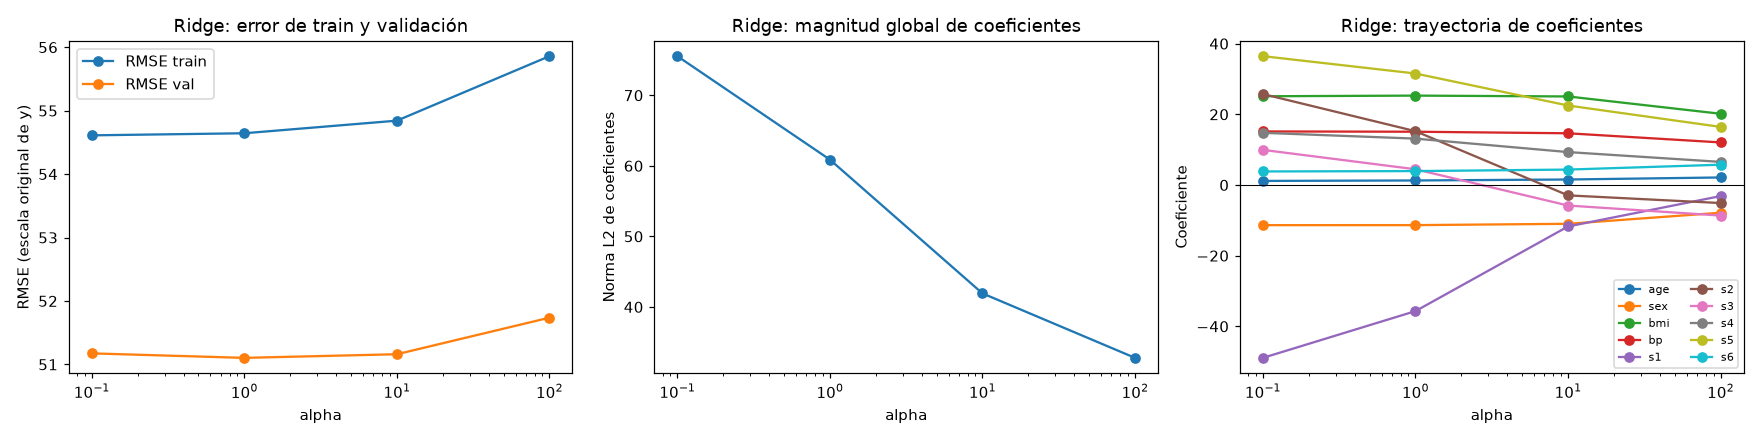

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reutilizar la búsqueda anterior, ordenada por intensidad de penalización.
tabla_regularizacion_ridge = resultados_ajustes_reg['Ridge'].sort_values("alpha").copy()
display(tabla_regularizacion_ridge[[
    "alpha", "MAE train", "MAE val", "RMSE train", "RMSE val",
    "Norma L2 coeficientes", "Coeficientes nulos"
]])

coeficientes_ridge = pd.DataFrame(
    tabla_regularizacion_ridge["Coeficientes"].tolist(),
    index=tabla_regularizacion_ridge["alpha"].to_numpy()
)
coeficientes_ridge.index.name = "alpha"
display(coeficientes_ridge)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for columna in ["RMSE train", "RMSE val"]:
    axes[0].plot(tabla_regularizacion_ridge["alpha"],
                 tabla_regularizacion_ridge[columna], marker="o", label=columna)
axes[0].set(xscale="log", xlabel="alpha", ylabel="RMSE (escala original de y)",
            title="Ridge: error de train y validación")
axes[0].legend()

axes[1].plot(tabla_regularizacion_ridge["alpha"],
             tabla_regularizacion_ridge["Norma L2 coeficientes"], marker="o")
axes[1].set(xscale="log", xlabel="alpha", ylabel="Norma L2 de coeficientes",
            title="Ridge: magnitud global de coeficientes")

for caracteristica in coeficientes_ridge.columns:
    axes[2].plot(coeficientes_ridge.index, coeficientes_ridge[caracteristica],
                 marker="o", label=caracteristica)
axes[2].axhline(0, color="black", linewidth=0.7)
axes[2].set(xscale="log", xlabel="alpha", ylabel="Coeficiente",
            title="Ridge: trayectoria de coeficientes")
axes[2].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()


#### Interpretación

La magnitud global de los coeficientes disminuye, pero no aparecen ceros exactos. El mejor RMSE de validación sigue en alpha=1.

#### Respuestas a las preguntas planteadas

**¿Qué ocurre al aumentar la penalización?**
Aumentar alpha restringe el ajuste, pero un exceso empeora validación.


### Regularización de Lasso

#### Predicción inicial

Creo que las variables que Lasso elimina son inútiles y quitarlas siempre mejorará la predicción.

#### Implementación y resultados


,alpha,MAE train,MAE val,RMSE train,RMSE val,Norma L2 coeficientes,Coeficientes nulos
0,0.01,43.794843,42.907269,54.610805,51.177697,76.051760,0
1,0.10,43.820002,42.642441,54.654421,51.099703,58.770809,0
2,1.00,44.115428,42.470345,54.912377,51.060247,41.985541,1
3,10.00,48.253951,45.144958,58.425064,53.151103,31.128626,6


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
alpha,,,,,,,,,,
0.01,1.136354,-11.348493,25.102718,15.153730,-49.346526,26.121962,10.067391,14.738517,36.652569,3.819039
0.10,1.176828,-11.251054,25.337227,15.031334,-33.574861,13.909548,3.120231,12.098388,31.089381,3.836335
1.00,0.333810,-9.539173,25.664674,14.196296,-11.507532,-0.000000,-6.936049,4.627055,24.460680,3.346866
10.00,0.000000,-0.000000,23.649283,6.533835,-0.000000,-0.000000,-3.785807,0.000000,18.779762,0.000000


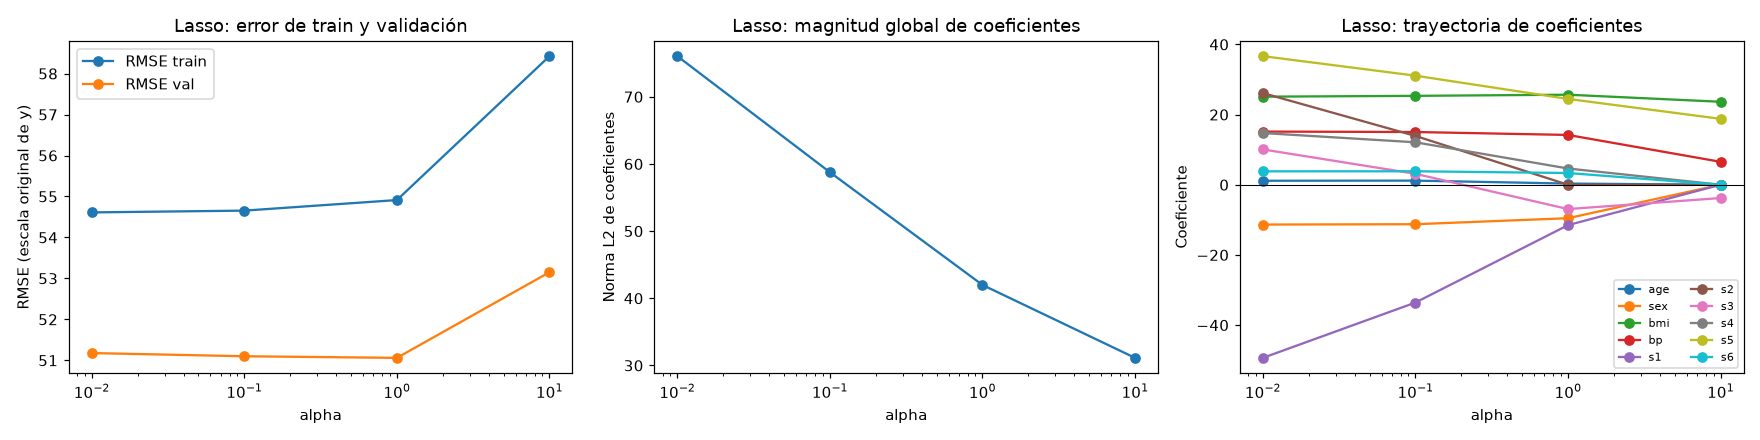

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reutilizar la búsqueda anterior, ordenada por intensidad de penalización.
tabla_regularizacion_lasso = resultados_ajustes_reg['Lasso'].sort_values("alpha").copy()
display(tabla_regularizacion_lasso[[
    "alpha", "MAE train", "MAE val", "RMSE train", "RMSE val",
    "Norma L2 coeficientes", "Coeficientes nulos"
]])

coeficientes_lasso = pd.DataFrame(
    tabla_regularizacion_lasso["Coeficientes"].tolist(),
    index=tabla_regularizacion_lasso["alpha"].to_numpy()
)
coeficientes_lasso.index.name = "alpha"
display(coeficientes_lasso)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for columna in ["RMSE train", "RMSE val"]:
    axes[0].plot(tabla_regularizacion_lasso["alpha"],
                 tabla_regularizacion_lasso[columna], marker="o", label=columna)
axes[0].set(xscale="log", xlabel="alpha", ylabel="RMSE (escala original de y)",
            title="Lasso: error de train y validación")
axes[0].legend()

axes[1].plot(tabla_regularizacion_lasso["alpha"],
             tabla_regularizacion_lasso["Norma L2 coeficientes"], marker="o")
axes[1].set(xscale="log", xlabel="alpha", ylabel="Norma L2 de coeficientes",
            title="Lasso: magnitud global de coeficientes")

for caracteristica in coeficientes_lasso.columns:
    axes[2].plot(coeficientes_lasso.index, coeficientes_lasso[caracteristica],
                 marker="o", label=caracteristica)
axes[2].axhline(0, color="black", linewidth=0.7)
axes[2].set(xscale="log", xlabel="alpha", ylabel="Coeficiente",
            title="Lasso: trayectoria de coeficientes")
axes[2].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()


#### Interpretación

Con alpha=1 se anula un coeficiente; con alpha=10 se anulan seis y aumenta el error de validación.

#### Respuestas a las preguntas planteadas

**¿Qué ocurre al aumentar la penalización?**
Un coeficiente cero depende del ajuste y no demuestra que una variable sea irrelevante ni que carezca de efecto causal.


### Regresión: ajuste de kNN

#### Predicción inicial

Creo que cinco vecinos y pesos por distancia ganarán porque se ajustan más a cada paciente.

#### Implementación y resultados


In [12]:
tabla_ajuste = comparar_configuraciones_reg('kNN', {'n_neighbors': [5, 10, 20], 'weights': ['uniform', 'distance']})
display(tabla_ajuste)


,n_neighbors,weights,Configuración,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val
5,20,distance,"{'n_neighbors': 20, 'weights': 'distance'}",0.000000,0.000000,1.000000,45.227804,54.394191,0.459970
4,20,uniform,"{'n_neighbors': 20, 'weights': 'uniform'}",45.480492,56.713703,0.482614,45.557865,54.553960,0.456793
2,10,uniform,"{'n_neighbors': 10, 'weights': 'uniform'}",42.857576,55.052216,0.512485,43.861798,54.639023,0.455098
3,10,distance,"{'n_neighbors': 10, 'weights': 'distance'}",0.000000,0.000000,1.000000,43.940124,54.803376,0.451814
0,5,uniform,"{'n_neighbors': 5, 'weights': 'uniform'}",41.348485,52.383979,0.558597,45.292135,56.833330,0.410452
1,5,distance,"{'n_neighbors': 5, 'weights': 'distance'}",0.000000,0.000000,1.000000,45.266686,57.163114,0.403590


#### Interpretación

El menor RMSE de validación se obtiene con 20 vecinos y pesos por distancia. Ajustar más train no asegura mejorar validación.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar n_neighbors=20 y weights="distance".


### Regresión: ajuste de Árbol

#### Predicción inicial

Creo que profundidad 5 y hojas pequeñas siempre serán mejores porque separan más casos.

#### Implementación y resultados


In [13]:
tabla_ajuste = comparar_configuraciones_reg('Árbol', {'max_depth': [2, 3, 5], 'min_samples_leaf': [1, 5]})
display(tabla_ajuste)


,max_depth,min_samples_leaf,Configuración,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val
3,3,5,"{'max_depth': 3, 'min_samples_leaf': 5, 'rando...",42.766247,53.896037,0.532747,46.921579,57.356508,0.399548
2,3,1,"{'max_depth': 3, 'min_samples_leaf': 1, 'rando...",43.105593,53.579488,0.538219,46.569194,58.226727,0.381189
0,2,1,"{'max_depth': 2, 'min_samples_leaf': 1, 'rando...",47.198513,57.627329,0.465810,46.680471,58.781439,0.369343
1,2,5,"{'max_depth': 2, 'min_samples_leaf': 5, 'rando...",47.198513,57.627329,0.465810,46.680471,58.781439,0.369343
4,5,1,"{'max_depth': 5, 'min_samples_leaf': 1, 'rando...",35.038690,45.139912,0.672237,47.079763,59.443386,0.355059
5,5,5,"{'max_depth': 5, 'min_samples_leaf': 5, 'rando...",33.045339,42.606036,0.708001,50.885035,63.342571,0.267674


#### Interpretación

Profundidad 3 y al menos cinco ejemplos por hoja obtienen el menor RMSE de validación.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar max_depth=3 y min_samples_leaf=5.


### Regresión: ajuste de Random Forest

#### Predicción inicial

Creo que quitar el límite de profundidad hará que el bosque mejore en todos los conjuntos.

#### Implementación y resultados


In [14]:
tabla_ajuste = comparar_configuraciones_reg('Random Forest', {'max_depth': [3, 5, None], 'min_samples_leaf': [1, 4]})
display(tabla_ajuste)


,max_depth,min_samples_leaf,Configuración,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val
0,3.0,1,"{'n_estimators': 100, 'max_depth': 3, 'min_sam...",40.591471,49.272372,0.609478,43.388406,53.814665,0.471416
1,3.0,4,"{'n_estimators': 100, 'max_depth': 3, 'min_sam...",40.634399,49.508376,0.605728,43.498819,53.847310,0.470774
5,NaN,4,"{'n_estimators': 100, 'max_depth': None, 'min_...",28.803938,36.028220,0.791203,43.958210,54.022150,0.467332
3,5.0,4,"{'n_estimators': 100, 'max_depth': 5, 'min_sam...",33.118216,40.734156,0.733095,43.557194,54.039163,0.466996
4,NaN,1,"{'n_estimators': 100, 'max_depth': None, 'min_...",18.442500,23.268282,0.912910,44.644719,54.290445,0.462028
2,5.0,1,"{'n_estimators': 100, 'max_depth': 5, 'min_sam...",31.340152,38.098294,0.766520,44.174741,54.700337,0.453874


#### Interpretación

Los árboles sin límite ajustan mejor train, pero profundidad 3 obtiene el menor RMSE de validación.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar 100 árboles, max_depth=3 y min_samples_leaf=1.


### Regresión: ajuste de Gradient Boosting

#### Predicción inicial

Creo que aprender más rápido siempre es mejor, así que learning_rate=0.1 debería ganar con 100 árboles.

#### Implementación y resultados


In [15]:
tabla_ajuste = comparar_configuraciones_reg('Gradient Boosting', {'n_estimators': [50, 100], 'learning_rate': [0.05, 0.1]})
display(tabla_ajuste)


,learning_rate,n_estimators,Configuración,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val
1,0.05,100,"{'n_estimators': 100, 'learning_rate': 0.05, '...",36.457473,44.642267,0.679424,43.192819,53.193285,0.483552
2,0.10,50,"{'n_estimators': 50, 'learning_rate': 0.1, 'ma...",36.360956,44.708155,0.678477,43.298591,53.334477,0.480807
0,0.05,50,"{'n_estimators': 50, 'learning_rate': 0.05, 'm...",41.440360,49.928947,0.599001,44.389988,53.931085,0.469126
3,0.10,100,"{'n_estimators': 100, 'learning_rate': 0.1, 'm...",30.584540,38.208602,0.765166,44.048708,53.973865,0.468284


#### Interpretación

Con 100 etapas, learning_rate=0.05 obtiene el menor RMSE de validación. Aprender más rápido no mejora aquí el resultado.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar 100 etapas, learning_rate=0.05 y max_depth=2.


### Regresión: ajuste de MLP

#### Predicción inicial

Creo que una red más grande siempre ganará y que escalar el objetivo hará que cualquier error sea pequeño.

#### Implementación y resultados


In [16]:
tabla_ajuste = comparar_configuraciones_reg('MLP', {'hidden_layer_sizes': [(8,), (16,), (32,)], 'alpha': [0.001, 0.01]})
display(tabla_ajuste)


,alpha,hidden_layer_sizes,Configuración,MAE train,RMSE train,R² train,MAE val,RMSE val,R² val
5,0.010,"(32,)","{'hidden_layer_sizes': (32,), 'alpha': 0.01, '...",43.207188,53.753591,0.535213,45.893317,55.021063,0.447451
2,0.001,"(32,)","{'hidden_layer_sizes': (32,), 'alpha': 0.001, ...",43.205283,53.752344,0.535235,45.898599,55.026791,0.447336
3,0.010,"(8,)","{'hidden_layer_sizes': (8,), 'alpha': 0.01, 'a...",44.835809,55.938221,0.496666,45.542980,55.262349,0.442594
0,0.001,"(8,)","{'hidden_layer_sizes': (8,), 'alpha': 0.001, '...",44.852859,55.956511,0.496337,45.542429,55.275459,0.442330
1,0.001,"(16,)","{'hidden_layer_sizes': (16,), 'alpha': 0.001, ...",45.021347,55.454450,0.505335,43.755129,55.306290,0.441707
4,0.010,"(16,)","{'hidden_layer_sizes': (16,), 'alpha': 0.01, '...",45.025800,55.458018,0.505271,43.760942,55.310741,0.441617


#### Interpretación

La mejor opción probada usa 32 neuronas y alpha=0.01. Sus errores se evalúan después de devolver y a la escala original.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Conservar esa configuración; escalar y no modifica la escala de las métricas finales.


### Regresión: selección y congelación

#### Predicción inicial

Creo que debo elegir los modelos por su menor error de train aunque validación indique lo contrario.

#### Implementación y resultados


In [17]:
configuraciones_finales_reg = {}
filas_seleccion_reg = []
for nombre, tabla in resultados_ajustes_reg.items():
    # Primera prioridad: RMSE; segunda: MAE. Orden estable para empates exactos.
    mejor = tabla.sort_values(["RMSE val", "MAE val"], kind="stable").iloc[0]
    configuraciones_finales_reg[nombre] = dict(mejor["Configuración"])
    filas_seleccion_reg.append({"Modelo": nombre,
        "Configuración congelada": configuraciones_finales_reg[nombre],
        "RMSE train": mejor["RMSE train"], "RMSE val": mejor["RMSE val"],
        "MAE val": mejor["MAE val"], "R² val": mejor["R² val"]})
tabla_seleccion_reg = pd.DataFrame(filas_seleccion_reg)
display(tabla_seleccion_reg)


,Modelo,Configuración congelada,RMSE train,RMSE val,MAE val,R² val
0,Regresión lineal,{},54.610364,51.193714,42.938900,0.521650
1,Ridge,{'alpha': 1.0},54.643849,51.103145,42.723050,0.523341
2,Lasso,"{'alpha': 1.0, 'max_iter': 10000}",54.912377,51.060247,42.470345,0.524140
3,kNN,"{'n_neighbors': 20, 'weights': 'distance'}",0.000000,54.394191,45.227804,0.459970
4,Árbol,"{'max_depth': 3, 'min_samples_leaf': 5, 'rando...",53.896037,57.356508,46.921579,0.399548
5,Random Forest,"{'n_estimators': 100, 'max_depth': 3, 'min_sam...",49.272372,53.814665,43.388406,0.471416
6,Gradient Boosting,"{'n_estimators': 100, 'learning_rate': 0.05, '...",44.642267,53.193285,43.192819,0.483552
7,MLP,"{'hidden_layer_sizes': (32,), 'alpha': 0.01, '...",53.753591,55.021063,45.893317,0.447451


### Configuraciones finales congeladas

Se conserva el menor RMSE de validación para cada modelo. No hubo que sacrificar ese criterio por una mejora exclusiva de train. El costo y la capacidad están limitados por las rejillas pequeñas; una menor brecha train–validación no es por sí sola el criterio de selección. La regresión lineal conserva su única configuración.

- **Regresión lineal:** `{}`.
- **Ridge:** `{'alpha': 1.0}`.
- **Lasso:** `{'alpha': 1.0, 'max_iter': 10000}`.
- **kNN:** `{'n_neighbors': 20, 'weights': 'distance'}`.
- **Árbol:** `{'max_depth': 3, 'min_samples_leaf': 5, 'random_state': 42}`.
- **Random Forest:** `{'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 1, 'random_state': 42}`.
- **Gradient Boosting:** `{'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'random_state': 42}`.
- **MLP:** `{'hidden_layer_sizes': (32,), 'alpha': 0.01, 'activation': 'relu', 'solver': 'adam', 'max_iter': 2000, 'early_stopping': True, 'random_state': 42}`.

Estas configuraciones quedan fijadas antes de evaluar test. Los modelos finales se entrenan con train, manteniendo el mismo protocolo que clasificación.


In [18]:
# Valores explícitos congelados: no se selecciona nada usando test.
configuraciones_congeladas_reg = {'Regresión lineal': {}, 'Ridge': {'alpha': 1.0}, 'Lasso': {'alpha': 1.0, 'max_iter': 10000}, 'kNN': {'n_neighbors': 20, 'weights': 'distance'}, 'Árbol': {'max_depth': 3, 'min_samples_leaf': 5, 'random_state': 42}, 'Random Forest': {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 1, 'random_state': 42}, 'Gradient Boosting': {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'random_state': 42}, 'MLP': {'hidden_layer_sizes': (32,), 'alpha': 0.01, 'activation': 'relu', 'solver': 'adam', 'max_iter': 2000, 'early_stopping': True, 'random_state': 42}}
modelos_finales_reg = {nombre: crear_modelo_regresion(nombre, parametros)
                       for nombre, parametros in configuraciones_congeladas_reg.items()}


#### Interpretación

Se elige el menor RMSE de validación para cada familia. Las configuraciones quedan fijadas antes de evaluar test.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
Usar modelos_finales_reg sin cambiar parámetros a partir del resultado de test.


### Regresión: evaluación final

#### Predicción inicial

Creo que el modelo que gana validación también ganará todas las métricas de test.

#### Implementación y resultados


In [19]:
resultados_test_reg = []
predicciones_test_reg = {}
for nombre, modelo in modelos_finales_reg.items():
    modelo.fit(X_train_reg, y_train_reg)
    pred_test = modelo.predict(X_test_reg)
    predicciones_test_reg[nombre] = pred_test
    resultados_test_reg.append({"Modelo": nombre, **metricas_regresion(y_test_reg, pred_test)})
tabla_test_reg = pd.DataFrame(resultados_test_reg)
display(tabla_test_reg)


,Modelo,MAE,RMSE,R²
0,Regresión lineal,42.924489,54.156413,0.446426
1,Ridge,42.970375,54.030853,0.448990
2,Lasso,42.721839,53.302410,0.463748
3,kNN,45.231569,55.250156,0.423841
4,Árbol,45.795414,57.428062,0.377522
5,Random Forest,42.895041,53.249837,0.464805
6,Gradient Boosting,43.093908,52.910339,0.471607
7,MLP,41.618080,53.085805,0.468097


### Resultados finales

| Modelo | MAE | RMSE | R² |
|---|---:|---:|---:|
| Regresión lineal | 42.9245 | 54.1564 | 0.4464 |
| Ridge | 42.9704 | 54.0309 | 0.4490 |
| Lasso | 42.7218 | 53.3024 | 0.4637 |
| kNN | 45.2316 | 55.2502 | 0.4238 |
| Árbol | 45.7954 | 57.4281 | 0.3775 |
| Random Forest | 42.8950 | 53.2498 | 0.4648 |
| Gradient Boosting | 43.0939 | 52.9103 | 0.4716 |
| MLP | 41.6181 | 53.0858 | 0.4681 |


#### Interpretación

Gradient Boosting obtiene el menor RMSE y el mayor R² en test; el MLP consigue el menor MAE.

#### Respuestas a las preguntas planteadas

**¿Qué decisión permite tomar este experimento?**
El ganador depende de la métrica; las configuraciones se mantienen congeladas aunque cambie el orden en test.


### Regresión: gráficos y errores grandes

#### Predicción inicial

Creo que todos los puntos quedarán cerca de la diagonal y que cualquier error grande será un dato mal registrado.

#### Implementación y resultados


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Real,Predicción,Error absoluto
56,-0.041840,-0.044642,0.041218,-0.026328,-0.03184,-0.030437,-0.036038,0.002943,0.033654,-0.017646,52.0,205.656245,153.656245
77,-0.096328,-0.044642,-0.036385,-0.074527,-0.03872,-0.027618,0.015505,-0.039493,-0.074093,-0.001078,200.0,68.971517,131.028483


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Real,Predicción,Error absoluto
56,-0.041840,-0.044642,0.041218,-0.026328,-0.03184,-0.030437,-0.036038,0.002943,0.033654,-0.017646,52.0,194.642461,142.642461
211,0.092564,-0.044642,0.036907,0.021872,-0.02496,-0.016658,0.000779,-0.039493,-0.022517,-0.021788,70.0,201.342062,131.342062


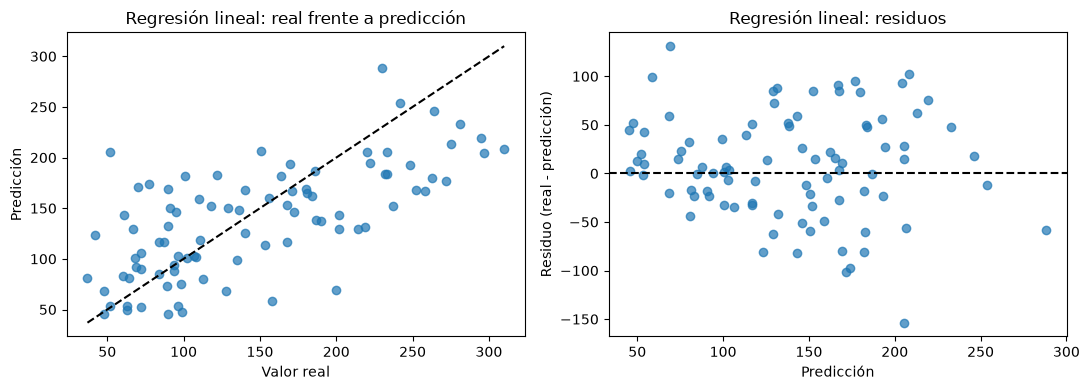

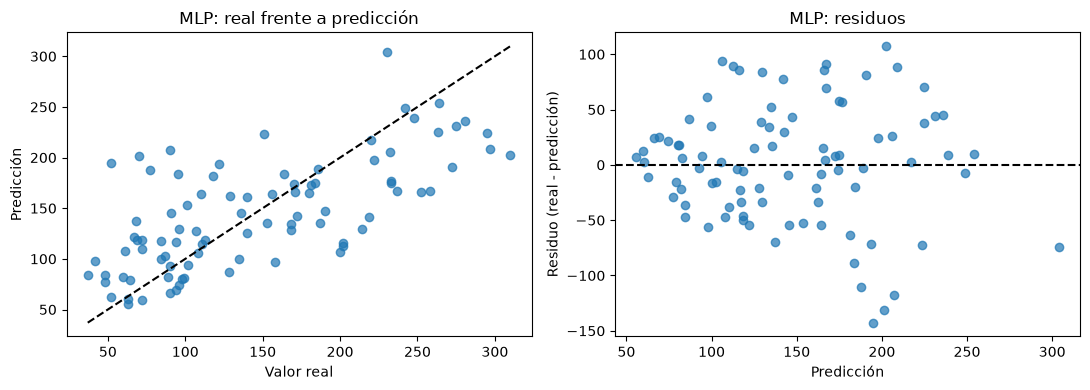

In [20]:
import matplotlib.pyplot as plt
for nombre in ["Regresión lineal", "MLP"]:
    pred = predicciones_test_reg[nombre]
    real = y_test_reg.to_numpy()
    residuos = real - pred
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].scatter(real, pred, alpha=0.7)
    limites = [min(real.min(), pred.min()), max(real.max(), pred.max())]
    axes[0].plot(limites, limites, "k--")
    axes[0].set(xlabel="Valor real", ylabel="Predicción", title=f"{nombre}: real frente a predicción")
    axes[1].scatter(pred, residuos, alpha=0.7)
    axes[1].axhline(0, color="black", linestyle="--")
    axes[1].set(xlabel="Predicción", ylabel="Residuo (real - predicción)", title=f"{nombre}: residuos")
    fig.tight_layout()
    indices = np.argsort(np.abs(residuos))[-2:][::-1]
    ejemplos = X_test_reg.iloc[indices].copy()
    ejemplos["Real"] = real[indices]
    ejemplos["Predicción"] = pred[indices]
    ejemplos["Error absoluto"] = np.abs(residuos[indices])
    display(ejemplos)
plt.show()


#### Interpretación

Hay predicciones alejadas del valor real en ambos modelos. Los casos mostrados no permiten atribuir una causa concreta.

#### Respuestas a las preguntas planteadas

**¿Qué se puede concluir de los errores grandes?**
Pueden faltar variables o existir casos difíciles; no se puede asegurar que los datos sean incorrectos.


### Respuestas finales de regresión

1. **Mejor desempeño:** Gradient Boosting tuvo el menor RMSE y el mayor R²; el MLP obtuvo el menor MAE.
2. **MAE frente a RMSE:** RMSE penaliza más los errores grandes, por eso puede favorecer un modelo diferente.
3. **R² negativo:** predice peor que responder siempre con el promedio de los valores reales del conjunto evaluado.
4. **Regularización:** redujo la magnitud de los coeficientes y Lasso anuló algunos; una penalización excesiva empeoró validación.
5. **Errores grandes:** pueden faltar variables o existir casos difíciles; no podemos asegurar una causa concreta.
6. **Causalidad:** un coeficiente predictivo indica asociación, pero no demuestra que cambiar esa variable cause un cambio en la enfermedad.
